In [1]:
import sys
sys.path.append("..")

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve
from src.woe import load_binners, woe_transform

train = pd.read_parquet("../data/processed/train.parquet")
test = pd.read_parquet("../data/processed/test.parquet")
binners = load_binners("../models/binners.joblib")
saved = joblib.load("../models/pd_model.joblib")
model, FINAL_VARS = saved["model"], saved["final_vars"]

for df in (train, test):
    X = woe_transform(df, binners)[FINAL_VARS]
    df["PD"] = model.predict_proba(X)[:, 1]

for name, df in [("Train", train), ("Test", test)]:
    auc = roc_auc_score(df["TARGET"], df["PD"])
    print(f"{name}: AUC {auc:.3f}, Gini {2 * auc - 1:.3f}, mean PD {df['PD'].mean():.2%}")

Train: AUC 0.746, Gini 0.492, mean PD 8.08%
Test: AUC 0.745, Gini 0.490, mean PD 8.07%


## ROC and CAP curves

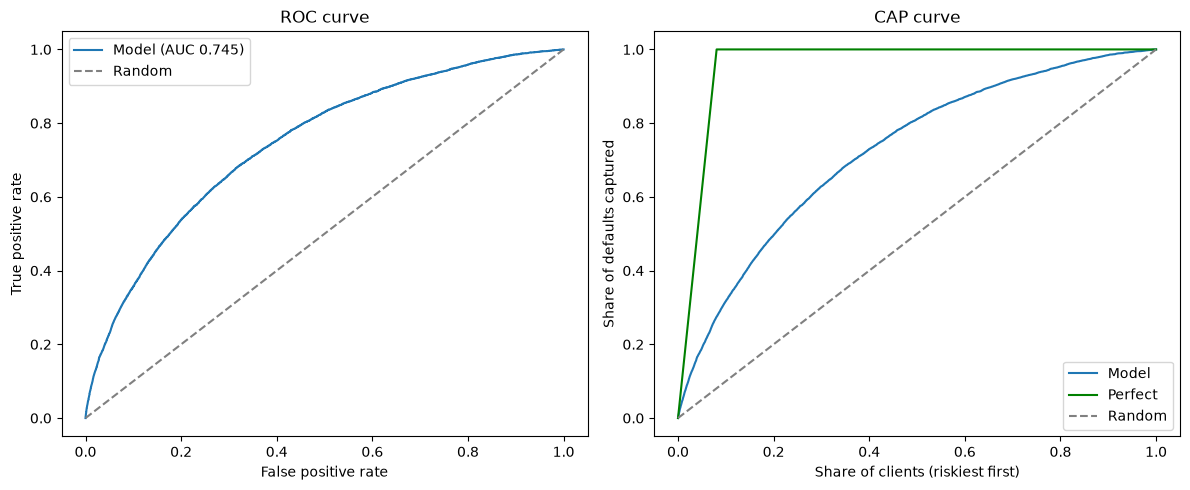

Accuracy ratio: 0.490


In [2]:
y, pd_test = test["TARGET"], test["PD"]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# ROC curve
fpr, tpr, _ = roc_curve(y, pd_test)
axes[0].plot(fpr, tpr, label=f"Model (AUC {roc_auc_score(y, pd_test):.3f})")
axes[0].plot([0, 1], [0, 1], "--", color="grey", label="Random")
axes[0].set(title="ROC curve", xlabel="False positive rate", ylabel="True positive rate")
axes[0].legend()

# CAP curve
order = np.argsort(-pd_test.values)
cum_defaults = np.cumsum(y.values[order]) / y.sum()
share = np.arange(1, len(y) + 1) / len(y)
default_rate = y.mean()
axes[1].plot(share, cum_defaults, label="Model")
axes[1].plot([0, default_rate, 1], [0, 1, 1], color="green", label="Perfect")
axes[1].plot([0, 1], [0, 1], "--", color="grey", label="Random")
axes[1].set(title="CAP curve", xlabel="Share of clients (riskiest first)", ylabel="Share of defaults captured")
axes[1].legend()

plt.tight_layout()
plt.show()

# Accuracy ratio from the CAP curve
area_model = np.trapezoid(cum_defaults, share) - 0.5
area_perfect = (1 - default_rate) / 2
print(f"Accuracy ratio: {area_model / area_perfect:.3f}")

**Discrimination:** test Gini 0.490 (AUC 0.745), close to the training Gini of 0.492, so there is no sign of overfitting. The accuracy ratio from the CAP curve equals the Gini, as expected.

## Calibrration

 clients predicted observed
PD_DECILE   
1 9226 1.28% 1.24%
2 9225 2.26% 2.50%
3 9225 3.11% 2.82%
4 9226 4.02% 3.86%
5 9225 5.09% 4.85%
6 9226 6.40% 6.55%
7 9225 8.10% 8.15%
8 9225 10.45% 10.68%
9 9226 14.35% 14.49%
10 9225 25.67% 25.60%



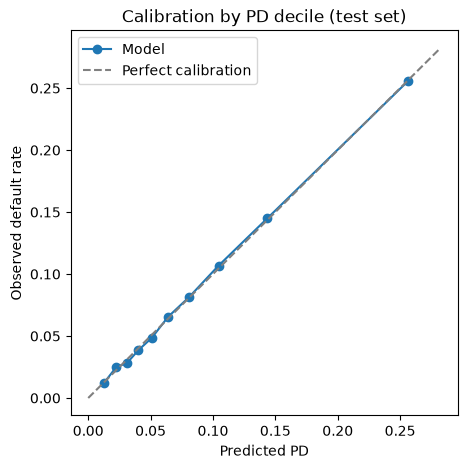

In [3]:
test["PD_DECILE"] = pd.qcut(test["PD"], 10, labels=False) + 1
calib = test.groupby("PD_DECILE").agg(
    clients=("TARGET", "size"),
    predicted=("PD", "mean"),
    observed=("TARGET", "mean"),
)
print(calib.style.format({"predicted": "{:.2%}", "observed": "{:.2%}"}).to_string())

plt.figure(figsize=(5, 5))
plt.plot(calib["predicted"], calib["observed"], "o-", label="Model")
lim = calib[["predicted", "observed"]].max().max() * 1.1
plt.plot([0, lim], [0, lim], "--", color="grey", label="Perfect calibration")
plt.xlabel("Predicted PD")
plt.ylabel("Observed default rate")
plt.title("Calibration by PD decile (test set)")
plt.legend()
plt.show()

**Calibration:** on the test set, predicted and observed default rates agree closely in every PD decile, within about 0.3 percentage points, with no systematic under- or overestimation. PDs range from about 1.3% in the safest decile to 25.7% in the riskiest.

Limitation: the test set comes from the same period as the training data (random split). A bank would also test calibration out-of-time, on later data, and adjust PDs for IFRS 9 (point-in-time, forward-looking) or CRR (long-run average).

## Stability, with the PSI, Population Stability Index

In [4]:
edges = np.quantile(train["PD"], np.linspace(0, 1, 11))
edges[0], edges[-1] = -np.inf, np.inf

expected = pd.cut(train["PD"], edges).value_counts(normalize=True, sort=False)
actual = pd.cut(test["PD"], edges).value_counts(normalize=True, sort=False)

psi = ((actual - expected) * np.log(actual / expected)).sum()
print(f"PSI (train vs test): {psi:.4f}")

PSI (train vs test): 0.0001


**Stability:** PSI between the training and test score distributions is 0.0001, far below the 0.1 threshold for a stable population. With a random split from the same period, this is expected; in practice, PSI is monitored over time to detect shifts in the client population that may require recalibration.

## Validation summary

| Test | Result | Assessment |
|---|---|---|
| Discrimination (test Gini) | 0.490 (AUC 0.745); train 0.492 | Good, no overfitting |
| Accuracy ratio (CAP) | 0.490 | Consistent with Gini |
| Calibration-in-the-large | Mean PD 8.07% vs observed 8.07% | Accurate |
| Calibration by decile | Within about 0.3 percentage points in every decile | Accurate, no systematic bias |
| Stability (PSI train vs test) | 0.0001 | Stable |

Main limitation: no out-of-time validation, since the data covers a single period.
